# BrushCue Example: Cross Hatch

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/cross_hatch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/cross-hatch

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


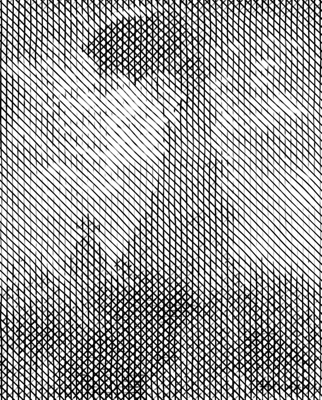

In [1]:
import io
from PIL import Image

import brushcue as bc

line_spacing = 18.0
ink_strength = 1.0
stroke_angle = 45.0
paper_texture = 0.25
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
reference_scale = (
    bc.Float.max(1.0, bc.Float.min(bounds.width(), bounds.height())) / 1000.0
)
spacing = bc.Float.max(3.0, (line_spacing * reference_scale))
graph = input_image.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2f(0.5);\nlet hi = image_bounds.zw - vec2f(0.5);\nlet p = clamp(position, lo, hi);\nlet source = sample(p);\nif (source.a <= 0.0) { return vec4f(0.0); }\n// A small alpha-weighted neighborhood calms pixel noise without filling cutouts.\nvar total = 0.0;\nvar weight = 0.0;\nfor (var y = -1; y <= 1; y = y + 1) {\n    for (var x = -1; x <= 1; x = x + 1) {\n        let c = sample(clamp(floor(p + vec2f(f32(x), f32(y)) * max(0.5, spacing * 0.16)) + vec2f(0.5), lo, hi));\n        let w = select(1.0, 2.0, x == 0) * select(1.0, 2.0, y == 0) * c.a;\n        total += luminance(c) * w;\n        weight += w;\n    }\n}\nlet gray = select(luminance(source), total / max(weight, 0.0001), weight > 0.0001);\nlet darkness = clamp(pow(1.0 - gray, 1.15) * ink_strength, 0.0, 1.0);\nlet uv = p - image_bounds.xy;\nvar paper = 1.0 - paper_texture * 0.045 * noise(uv / max(reference_scale, 0.5));\n// Each additional direction enters smoothly as the source tone becomes darker.\nfor (var layer = 0; layer < 4; layer = layer + 1) {\n    let angle = stroke_angle * 0.0174532925 + f32(layer) * 0.7853981634;\n    let direction = vec2f(cos(angle), sin(angle));\n    let normal = vec2f(-direction.y, direction.x);\n    let along = dot(uv, direction);\n    let across = dot(uv, normal);\n    let bend = (noise(vec2f(along / (spacing * 5.0), across / (spacing * 3.0)) + f32(layer) * 17.0) - 0.5) * spacing * 0.28;\n    let coordinate = (across + bend) / spacing + f32(layer) * 0.23;\n    let distance = abs(fract(coordinate + 0.5) - 0.5) * spacing;\n    let variation = 0.85 + 0.3 * noise(vec2f(along / (spacing * 2.0), floor(coordinate)));\n    let half_width = spacing * (0.075 + 0.075 * darkness) * variation;\n    // Analytic pixel coverage also works in compute shaders without derivatives.\n    let line = 1.0 - smoothstep(max(0.0, half_width - 0.6), half_width + 0.6, distance);\n    let start = f32(layer) * 0.22;\n    let coverage = smoothstep(start, start + 0.28, darkness);\n    paper *= 1.0 - line * coverage * 0.94;\n}\nreturn vec4f(vec3f(clamp(paper, 0.0, 1.0)), source.a);",
    "fn hash(p: vec2f) -> f32 {\n    let q = fract(p * vec2f(0.1031, 0.11369));\n    let n = dot(q, q.yx + vec2f(19.19));\n    return fract((q.x + q.y + n) * (q.x + n));\n}\nfn noise(p: vec2f) -> f32 {\n    let i = floor(p);\n    let f = fract(p);\n    let u = f * f * (vec2f(3.0) - 2.0 * f);\n    return mix(mix(hash(i), hash(i + vec2f(1.0, 0.0)), u.x),\n        mix(hash(i + vec2f(0.0, 1.0)), hash(i + vec2f(1.0)), u.x), u.y);\n}\nfn luminance(c: vec4f) -> f32 {\n    return dot(clamp(c.rgb, vec3f(0.0), vec3f(1.0)), vec3f(0.299, 0.587, 0.114));\n}",
    0.0,
    bc.Dictionary.create()
    .add("image_bounds", bounds)
    .add("reference_scale", reference_scale)
    .add("spacing", spacing)
    .add("ink_strength", ink_strength)
    .add("stroke_angle", stroke_angle)
    .add("paper_texture", paper_texture),
    bc.ColorRepresentation.srgb(),
).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
